
# Lab 7: Fast Fourier Transform (FFT)

 **Example 1** : Chord - musical sound: Do mayor. Done in class.

![Do mayor](https://upload.wikimedia.org/wikipedia/commons/7/79/Major_chord_on_C.png)

Load the Nota_CM_piano.mp3 file from a Do mayor sound:
1. Do the FFT using scipy and Numpy rutines (see notebook)
2. Used the rutine created in class `FT(x,y)`. Modify it and do the FT to the signal. Do you get the same results?


 **Exercise 1** : Do the FFT for an Imagen

Choose an Imagen

1. Do the FFT using scipy-numpy (see notebook)
2. Used the rutine created in class `FT(x,y)`. Modify it and do the FT for the signal. Do you get the same results?
3. Do the inverse FFT and reconstruc the original imagene. <br> Do you get a similar result? Compare the original and the reconstructed signal.


In [1]:
from google.colab import drive
from PIL import Image

drive.mount('/content/drive')

Mounted at /content/drive


In [79]:
import numpy as np
import pandas as pd
import librosa
import matplotlib.pyplot as plt
import scipy.io.wavfile
from scipy.fft import fft, ifft, fft2, ifft2, fftshift, ifftshift
import scipy.integrate as integrate
from IPython.display import Audio

In [9]:
# FT definida en clase Modificada

# Base continua:

def g(t,w):
   return 1./(2*np.pi)*np.exp(-1j*2*np.pi*w*t)

# Transformada de Fourier

def FT_mod(x,y,f_max,f_min,n):

  w = np.linspace(f_min,f_max,n) # Frecuencias a evalua4

  df = []

  for i in range(len(w)):
    # Función por la base de Fourier

    integrando_re = y*g(x,w[i]).real
    integrando_im = y*g(x,w[i]).imag

    # Integramos el producto de la función por la base de Fourier

    parte_re = integrate.trapezoid(integrando_re,x)
    parte_im = integrate.trapezoid(integrando_im,x)

    A = np.sqrt(parte_re**2+parte_im**2)
    ang = np.arctan(parte_im/parte_re)

    df.append([w[i], parte_re, parte_im, A, ang]) # DataFrame para ordenar los datos


  df = pd.DataFrame(df, columns=['w', 'ReTw', 'ImTw', 'AMP', 'ANG'])

  return df

In [22]:
# Subimos el audio a analizar

y_audio, sr = librosa.load("/content/drive/MyDrive/Udea/Física Computacional 1/Nota_CM_piano.mp3")
t_audio = np.arange(len(y_audio)) / sr

muestra = int(0.1 * sr)

t_cut = t_audio[:muestra]
y_cut = y_audio[:muestra]

print('Frecuencia de muestreo:', sr)
print('Número total de muestras:', len(y_audio))
print('Muestras utilizadas:', len(y_cut))

Frecuencia de muestreo: 22050
Número total de muestras: 76032
Muestras utilizadas: 2205


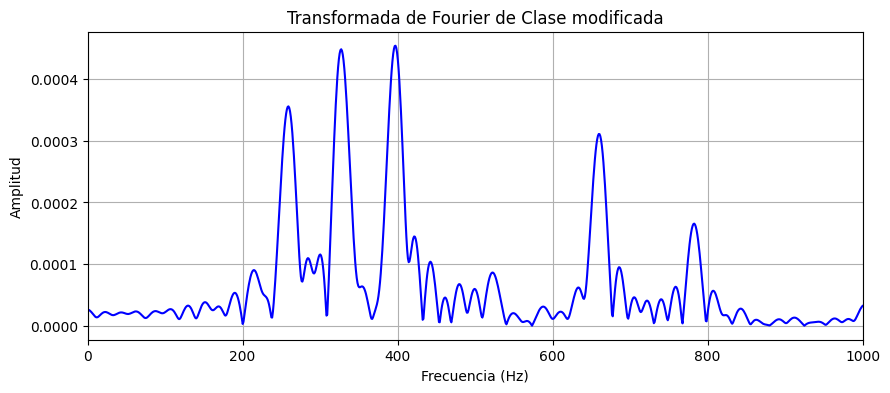

In [27]:
df_resultado = FT_mod(
    x = t_cut,
    y = y_cut,
    f_max = 1000,
    f_min = 0,
    n = 1000
)

plt.figure(figsize=(10, 4))

plt.plot(df_resultado['w'], df_resultado['AMP'], color='blue')

plt.title('Transformada de Fourier de Clase modificada')
plt.xlabel('Frecuencia (Hz)')
plt.ylabel('Amplitud')
plt.xlim(0, 1000)
plt.grid()

plt.show()

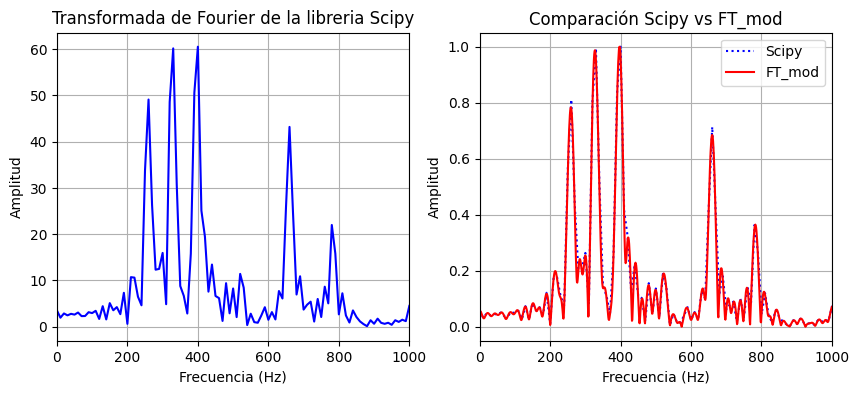

In [39]:
from matplotlib.lines import lineStyles
# FT por libreria Scipy
y_fft = fft(y_cut)

# frecuencias de FFT
x_fft = np.linspace(0, sr, len(y_fft))

# Amplitud de la FFT Scipy
freq_FFT = x_fft
AMP_FFT = 2.0/len(y_cut)*np.abs(y_fft)

# Amplitud de FT_mod

freq_FT_mod = df_resultado['w']
AMP_FT_mod = df_resultado['AMP']

# Normalización de ambas transformadas

AMP_FFT = AMP_FFT/np.max(AMP_FFT)
AMP_FT_mod = AMP_FT_mod/np.max(AMP_FT_mod)

# Grafica de FFT Scipy y comparación entre Scipy y FT_mod

plt.figure(figsize=(10, 4))

plt.subplot(1, 2, 1)
plt.plot(x_fft, np.abs(y_fft), color='blue')
plt.title('Transformada de Fourier de la libreria Scipy')
plt.xlabel('Frecuencia (Hz)')
plt.ylabel('Amplitud')
plt.xlim(0, 1000)
plt.grid()

plt.subplot(1, 2, 2)
plt.plot(freq_FFT, AMP_FFT, color='blue', linestyle = ":", label="Scipy")
plt.plot(freq_FT_mod, AMP_FT_mod, color='red', label="FT_mod")
plt.legend()

plt.title('Comparación Scipy vs FT_mod')
plt.xlabel('Frecuencia (Hz)')
plt.ylabel('Amplitud')
plt.xlim(0, 1000)
plt.grid()


plt.show()

Tanto Scipy como FT_mod obtienen la misma transformada, las pequeñas discrepancias entre ambas se deben a que FT_mod devuelve un resultado más suave que Scipy, sin embargo ambas alcanzan los mismos picos en intervalo de 0 Hz y 1 KHz.

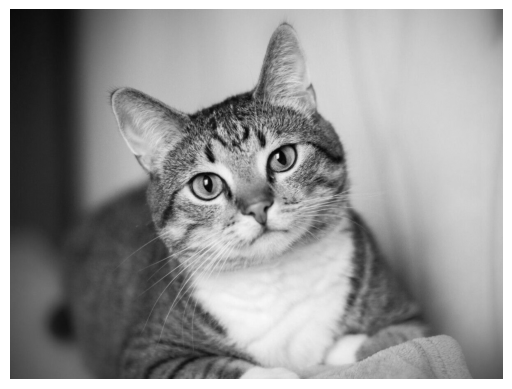

(900, 1200)


In [70]:
# Subimos la imagen a analizar y audio a analizar

img = Image.open("/content/drive/MyDrive/Udea/Física Computacional 1/gato.jpg")

imagen = np.array(img) # Imagen vuelta matriz

# Pasar a escala de grises

if len(imagen.shape) == 3:
    imagen = np.mean(imagen[:, :, :3], axis=2)

imagen = imagen.astype(np.float32)

plt.imshow(imagen, cmap='gray')
plt.axis('off')
plt.show()

print(imagen.shape)

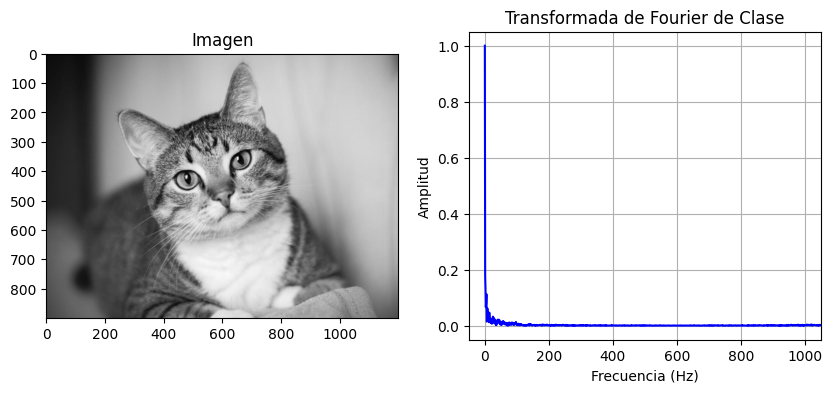

In [71]:
# Tomamos una fila de la mitad de la matriz

fila_mid = int(imagen.shape[0] / 2)
fila = imagen[fila_mid, :]
signal_1d = imagen[fila_mid,:]

x_pixeles = np.arange(len(signal_1d)) # De pixeles a coordenadas

# Usamos FT_mod

df_resultado_1d = FT_mod(
    x = x_pixeles,
    y = signal_1d,
    f_max = 1200,
    f_min = 0,
    n = 1200 # Mismo número de pixeles horizontales
)

# Usamos Scipy

y_fft = fft(signal_1d)

# frecuencias de FFT
x_fft = np.linspace(0, len(signal_1d), len(y_fft))

plt.figure(figsize=(10, 4))
plt.subplot(1, 2, 1)
plt.imshow(imagen, cmap='gray')
plt.title('Imagen')

plt.subplot(1, 2, 2)
plt.plot(df_resultado_1d['w'], df_resultado_1d['AMP']/df_resultado_1d['AMP'].max(), color='blue')
plt.title('Transformada de Fourier de Clase')
plt.xlabel('Frecuencia (Hz)')
plt.ylabel('Amplitud')
plt.xlim(-50, 1050)
plt.grid()

plt.show()

/usr/local/lib/python3.13/dist-packages/matplotlib/cbook.py:1709: ComplexWarning: Casting complex values to real discards the imaginary part
  return math.isfinite(val)
/usr/local/lib/python3.13/dist-packages/matplotlib/cbook.py:1345: ComplexWarning: Casting complex values to real discards the imaginary part
  return np.asarray(x, float)


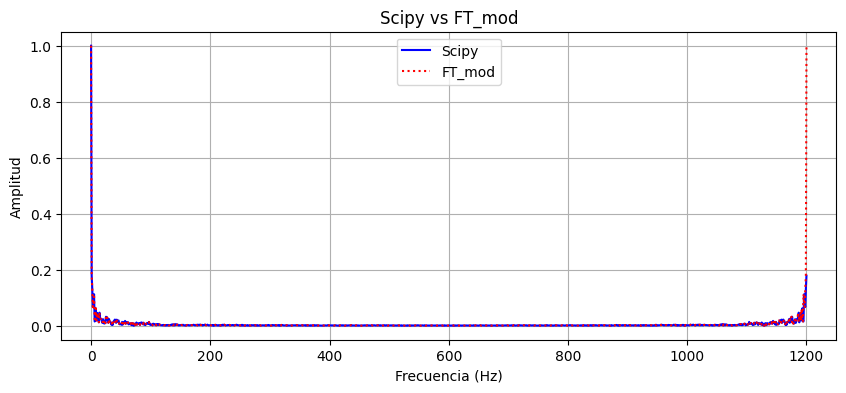

In [75]:
plt.figure(figsize=(10, 4))
plt.plot(x_fft, np.abs(y_fft)/y_fft.max(), color='blue', label="Scipy")
plt.plot(df_resultado_1d['w'], df_resultado_1d['AMP']/df_resultado_1d['AMP'].max(), color='red',
         linestyle = ":", label="FT_mod")
plt.legend()
plt.title('Scipy vs FT_mod')
plt.xlabel('Frecuencia (Hz)')
plt.ylabel('Amplitud')
plt.xlim(-50, 1250)
plt.grid()
plt.show()


Al igual que para el analisis del audio, FT_mod y FFT de Scipy obtuvieron el mismo resultado, la unica discrepancia es el tamaño del pico en cerca de 1200 Hz, pero dado que es un valor limite, se puede atribuir a eso mismo y concluir que FT_mod y FFT Scipy obtienen la misma transformada de Fourier.

Error maximo:  0.0001525918


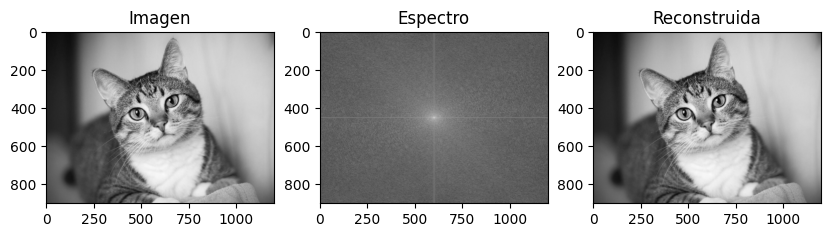

In [82]:
# Cálculo de la tranformada de Fourier 2D de la imagen completa

f_imagen = fft2(imagen) # FT de la imagen completa

espectro = np.log1p(np.abs(fftshift(f_imagen))) # Espectro de la imagen

imagen_recon = ifft2(f_imagen) # Reconstrucción de la imagen completa

error_max = np.max(np.abs(imagen-imagen_recon)) # Error máximo entre la imagen original y la reconstruida

print("Error maximo: ", error_max)

plt.figure(figsize=(10, 4))
plt.subplot(1, 3, 1)
plt.imshow(imagen, cmap='gray')
plt.title('Imagen')

plt.subplot(1, 3, 2)
plt.imshow(espectro, cmap='gray')
plt.title('Espectro')

plt.subplot(1, 3, 3)
plt.imshow(np.abs(imagen_recon), cmap='gray')
plt.title('Reconstruida')

plt.show()

El error entre la imagen original y la recontrucción es despreciable, la perdida de información entre FFT2 es muy baja, por lo que obtenemos de forma muy bien aproximada la misma imagen.